**Импорт библиотек**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

**Загрузка данных**

 Датасет teleCust.csv содержит информацию о 1000 клиентах телеком-компании.
 Целевая переменная — custcat (категория клиента: 1, 2, 3, 4).
 Мы хотим предсказывать, к какой категории услуг относится новый клиент.

In [3]:
df = pd.read_csv("teleCust.csv")
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


**Получаем набор данных**

 Выводим распределение каждого признака.
 
 Это помогает понять:
 - есть ли дисбаланс классов
 - какие признаки категориальные
 - есть ли выбросы

In [4]:
for i in df.columns:
    print(i)
    print(df[i].value_counts())
    print("----------------------------")

region
region
3    344
2    334
1    322
Name: count, dtype: int64
----------------------------
tenure
tenure
72    31
48    20
24    20
3     20
13    19
      ..
47     7
36     7
2      7
21     6
63     6
Name: count, Length: 72, dtype: int64
----------------------------
age
age
33    39
39    35
35    34
34    32
31    32
37    31
42    28
40    28
30    26
52    25
36    25
46    24
48    24
27    24
43    24
41    24
54    24
45    24
51    23
50    23
25    23
28    22
32    21
47    21
26    21
55    21
38    21
44    20
57    20
24    20
29    19
53    19
49    18
23    16
22    15
59    14
63    12
60    11
56    11
61    11
58    10
64    10
20    10
62     9
21     8
66     7
68     6
69     6
65     6
67     5
19     4
76     3
70     3
75     2
71     1
72     1
74     1
77     1
18     1
73     1
Name: count, dtype: int64
----------------------------
marital
marital
0    505
1    495
Name: count, dtype: int64
----------------------------
address
address
1     68
2     6

 **Удаляем ненужные признаки**
 
 Убираем 'ed' (образование) и 'employ' (стаж работы).
 Они сильно коррелируют с другими признаками и могут ухудшить качество модели.

In [6]:
df.drop(["ed", "employ"], axis = 1, inplace = True)

In [7]:
df.head()

,region,tenure,age,marital,address,income,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,0.0,0,2,1
1,3,11,33,1,7,136.0,0.0,0,6,4
2,3,68,52,1,24,116.0,0.0,1,2,3
3,2,33,33,0,12,33.0,0.0,1,1,1
4,2,23,30,1,9,30.0,0.0,0,4,3


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   region   1000 non-null   int64  
 1   tenure   1000 non-null   int64  
 2   age      1000 non-null   int64  
 3   marital  1000 non-null   int64  
 4   address  1000 non-null   int64  
 5   income   1000 non-null   float64
 6   retire   1000 non-null   float64
 7   gender   1000 non-null   int64  
 8   reside   1000 non-null   int64  
 9   custcat  1000 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 78.3 KB


**Кореляция тепловой карты**

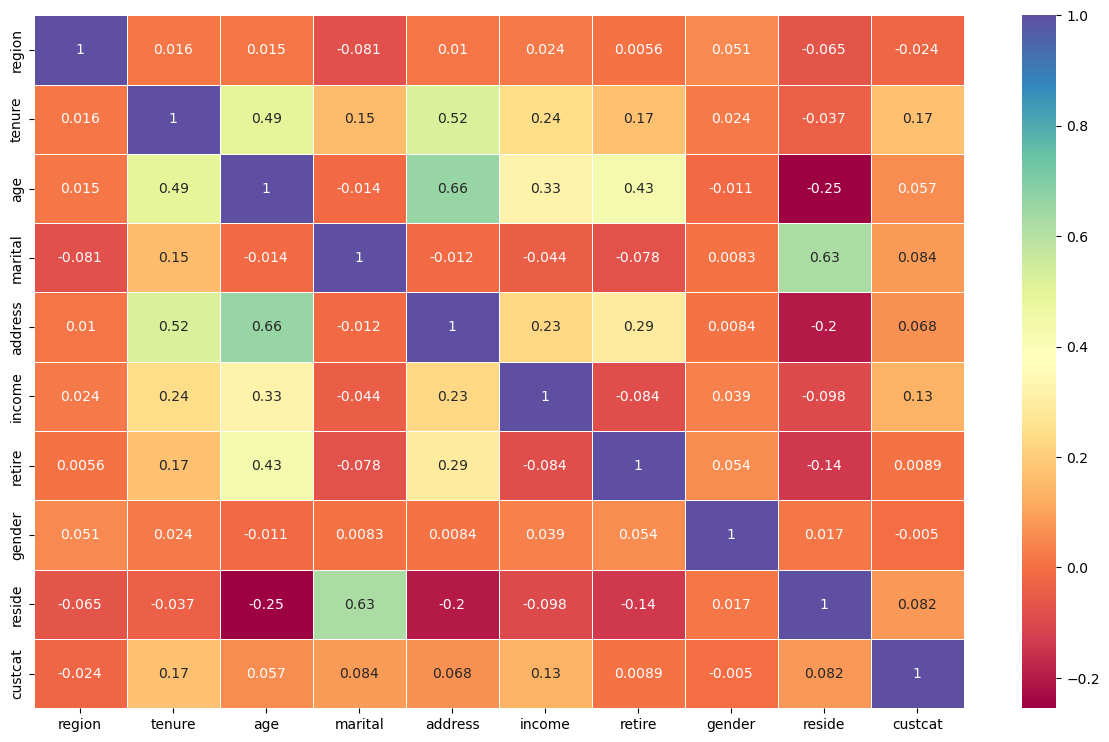

In [9]:
plt.figure(figsize = (15, 9))
sns.heatmap(df.corr(), annot = True, linewidth = 0.5, cmap = "Spectral")
plt.show()

In [10]:
df.drop(["retire", "gender"], axis = 1, inplace = True)

In [11]:
df.head()

,region,tenure,age,marital,address,income,reside,custcat
0,2,13,44,1,9,64.0,2,1
1,3,11,33,1,7,136.0,6,4
2,3,68,52,1,24,116.0,2,3
3,2,33,33,0,12,33.0,1,1
4,2,23,30,1,9,30.0,4,3


 **Кодирование категориальных признаков (One-Hot Encoding)**
                                         
 Region и reside — категориальные.
 Превращаем их в бинарные столбцы (True/False).
 Это необходимо, потому что KNN работает только с числовыми признаками.

In [12]:
region = pd.get_dummies(df["region"], drop_first = True, prefix = "region")
reside = pd.get_dummies(df["reside"], drop_first = True, prefix = "reside")

In [13]:
df.drop(["region", "reside"], axis = 1, inplace = True)

In [14]:
df = pd.concat([df, region, reside], axis = 1)

In [15]:
df.head()

,tenure,age,marital,address,income,custcat,region_2,region_3,reside_2,reside_3,reside_4,reside_5,reside_6,reside_7,reside_8
0,13,44,1,9,64.0,1,True,False,True,False,False,False,False,False,False
1,11,33,1,7,136.0,4,False,True,False,False,False,False,True,False,False
2,68,52,1,24,116.0,3,False,True,True,False,False,False,False,False,False
3,33,33,0,12,33.0,1,True,False,False,False,False,False,False,False,False
4,23,30,1,9,30.0,3,True,False,False,False,True,False,False,False,False


**Стантартизация переменной**

In [16]:
from sklearn.preprocessing import StandardScaler

In [18]:
scaled_variable = df[["tenure", "age", "address", "income"]]

In [19]:
scaled_variable

,tenure,age,address,income
0,13,44,9,64.0
1,11,33,7,136.0
2,68,52,24,116.0
3,33,33,12,33.0
4,23,30,9,30.0
...,...,...,...,...
995,10,39,0,27.0
996,7,34,2,22.0
997,67,59,40,944.0
998,70,49,18,87.0


In [20]:
scaler = StandardScaler()

In [21]:
scaler.fit(scaled_variable)

StandardScaler()

In [22]:
scaled_variable = scaler.transform(scaled_variable)

In [24]:
df_scaled = pd.DataFrame(scaled_variable, columns = ["tenure", "age", "address", "income"])

In [26]:
df_scaled.head()

,tenure,age,address,income
0,-1.055125,0.184505,-0.253034,-0.126506
1,-1.148806,-0.691812,-0.451415,0.546450
2,1.521092,0.821826,1.234819,0.359517
3,-0.118319,-0.691812,0.044536,-0.416251
4,-0.586722,-0.930808,-0.253034,-0.444291


In [27]:
df.head()

,tenure,age,marital,address,income,custcat,region_2,region_3,reside_2,reside_3,reside_4,reside_5,reside_6,reside_7,reside_8
0,13,44,1,9,64.0,1,True,False,True,False,False,False,False,False,False
1,11,33,1,7,136.0,4,False,True,False,False,False,False,True,False,False
2,68,52,1,24,116.0,3,False,True,True,False,False,False,False,False,False
3,33,33,0,12,33.0,1,True,False,False,False,False,False,False,False,False
4,23,30,1,9,30.0,3,True,False,False,False,True,False,False,False,False


In [28]:
df.drop(["tenure", "age", "address", "income"], axis =1, inplace = True)

In [31]:
df = pd.concat([df, df_scaled], axis = 1)

In [32]:
df.head()

,marital,custcat,region_2,region_3,reside_2,reside_3,reside_4,reside_5,reside_6,reside_7,reside_8,tenure,age,address,income
0,1,1,True,False,True,False,False,False,False,False,False,-1.055125,0.184505,-0.253034,-0.126506
1,1,4,False,True,False,False,False,False,True,False,False,-1.148806,-0.691812,-0.451415,0.546450
2,1,3,False,True,True,False,False,False,False,False,False,1.521092,0.821826,1.234819,0.359517
3,0,1,True,False,False,False,False,False,False,False,False,-0.118319,-0.691812,0.044536,-0.416251
4,1,3,True,False,False,False,True,False,False,False,False,-0.586722,-0.930808,-0.253034,-0.444291


**KNN Моделирование**

In [33]:
X = df.drop(["custcat"], axis =1)
y = df["custcat"]

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [36]:
print("Train set:", X_train.shape, y_train.shape)
print("Train set:", X_test.shape, y_test.shape)

Train set: (800, 14) (800,)
Train set: (200, 14) (200,)


In [37]:
from sklearn.neighbors import KNeighborsClassifier

In [38]:
k = 4
knn_model = KNeighborsClassifier(n_neighbors = k)
knn_model.fit(X_train, y_train)
knn_model

KNeighborsClassifier(n_neighbors=4)

In [40]:
y_pred = knn_model.predict(X_test)

In [41]:
from sklearn import metrics
print("Accuracy score:", metrics.accuracy_score(y_test, y_pred))

Accuracy score: 0.325


In [42]:
k = 6
knn_model2 = KNeighborsClassifier(n_neighbors = k)
knn_model2.fit(X_train, y_train)
knn_model2

KNeighborsClassifier(n_neighbors=6)

In [ ]:
y_pred = knn_model2.predict(X_test)